# 04 · Diagnostic — a verdict for every branch, against a measured noise floor

**Stage 5a, Path A.** The question this notebook answers is not "which features are significant?"
It is the harder one:

> **Which features carry more signal than a column we have already proven to be random?**

`02_cleaning` §2.1 showed why the usual test is not enough: `DailyRate` — uniform random numbers,
convicted on four independent tests — scores a univariate AUC of 0.545 against attrition for a
permutation **p = 0.026**. It passes conventional significance. Any procedure that would call that
a driver will call several other things drivers too.

So this notebook does three things in order, and the order matters:

| § | Step | Why it must come first |
|---|---|---|
| 4.1 | Build a **per-feature permutation null** — 23 real features + 3 placebos + 20 synthetic columns | The floor is fixed *before* any feature is judged, so no threshold is chosen after seeing which features it would eliminate |
| 4.2 | Rank every feature against its own null, FDR-corrected | Cardinality and tie structure change the null — a 9-level category is not judged against a binary's null |
| 4.3–4.5 | Effect sizes, the pay decomposition, and mutual adjustment | Significance is not size; size is not independence |

**Framing, stated here and not only in the report:** every result below is an **association** in a
single cross-sectional snapshot. There are no hire dates, no exit dates, and no assignment
mechanism, so nothing here identifies a causal effect. Path C is out of scope by design.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

SRC_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
PROC, REP, FIG = ROOT / "data" / "processed", ROOT / "reports", ROOT / "reports" / "figures"

# --- DESIGN.md palette + rcParams, defined inline (no src/ import, per the plan) ---
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CAT_ORDER = [BLUE, TEAL, AMBER, CYAN, SLATE]
# Semantic mapping for this project (fixed in IMPLEMENTATION_PLAN.md S7.2):
LEAVER, STAYER, PLACEBO, MARKER = BLUE, TEAL, GREY, AMBER

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "figure.facecolor": "white",
    "savefig.facecolor": "white", "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 9, "text.color": NAVY,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5,
})


def figsave(fig, name):
    """Save an exhibit to reports/figures/ under its exhibit id."""
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{name}.png")
    print("saved:", name + ".png")


df = pd.read_parquet(PROC / "hr_clean.parquet")
contract = pd.read_csv(PROC / "_column_contract.csv")
y = df.Attrition_flag.to_numpy()
BASE = y.mean()

# BusinessTravel is the one ordinal column stored as text. The contract (02_cleaning S2.3) licensed
# ordinal treatment on monotonicity evidence (8.0% -> 15.0% -> 24.9%), so it is encoded here once.
TRAVEL_MAP = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
df["BusinessTravel"] = df.BusinessTravel.map(TRAVEL_MAP).astype(int)

FEATURES = contract[contract.role.isin(["feature", "placebo"])].copy()
BR = dict(zip(FEATURES.column, FEATURES.branch))
SCALE = dict(zip(FEATURES.column, FEATURES.scale))
ROLE = dict(zip(FEATURES.column, FEATURES.role))
NOMINAL = [c for c in FEATURES.column if SCALE[c] == "nominal"]
ORDERED = [c for c in FEATURES.column if SCALE[c] in ("numeric", "ordinal")]

BRANCH_NAME = {"A": "A · Fixed traits", "B": "B · Role & structure", "C": "C · Compensation",
               "D": "D · Workload", "E": "E · Tenure", "F": "F · Engagement (Scope 2)",
               "Z": "Z · Placebo control"}
BRANCH_COLOR = {"A": SLATE, "B": TEAL, "C": MARKER, "D": LEAVER, "E": CYAN,
                "F": "#7B61FF", "Z": PLACEBO}

print(f"{len(df):,} employees, {int(y.sum())} leavers ({BASE:.1%})")
print(f"features under test: {len(FEATURES)}  "
      f"({len(ORDERED)} ordered, {len(NOMINAL)} nominal, "
      f"{sum(r == 'placebo' for r in ROLE.values())} placebo)")

1,470 employees, 237 leavers (16.1%)
features under test: 30  (23 ordered, 7 nominal, 3 placebo)


## 4.1 The noise floor, built before anything is judged

### Why one global floor is not good enough

A rank-based AUC null depends on the feature's **tie structure**. A binary column, a 4-level Likert
scale and a continuous one do not share a null distribution, and a 9-level nominal category encoded
by its group attrition rate can manufacture apparent separation purely from having many small
groups to overfit.

So each feature is judged against **its own** permutation null: shuffle the labels, recompute *that
feature's* score exactly as it was computed on the real data, repeat. Two scoring functions, matched
to the measurement scale from the contract:

- **Ordered features** (numeric + ordinal) — direction-free rank AUC, `max(AUC, 1−AUC)`.
- **Nominal features** — **out-of-fold** AUC under group-rate encoding, so a 9-level column is
  scored on held-out data and cannot buy separation with cardinality alone.

The three placebo columns then act as a **live validation of the machinery**: if the null is built
correctly, they should land near the middle of it.

In [2]:
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(CV.split(np.zeros(len(df)), y))


def score_ordered(x, target):
    a = roc_auc_score(target, x)
    return max(a, 1 - a)


def score_nominal(x, target):
    # Out-of-fold AUC under group-rate (target) encoding - honest for high cardinality.
    oof = np.empty(len(target), float)
    for tr, te in FOLDS:
        rates = pd.Series(target[tr]).groupby(pd.Series(x[tr]).to_numpy()).mean()
        prior = target[tr].mean()
        oof[te] = pd.Series(x[te]).map(rates).fillna(prior).to_numpy()
    return roc_auc_score(target, oof)


def score_of(col, values, target):
    return score_nominal(values, target) if SCALE[col] == "nominal" else score_ordered(values, target)


N_PERM_ORD, N_PERM_NOM = 2000, 400
print(f"permutations: {N_PERM_ORD:,} for ordered features, {N_PERM_NOM} for nominal "
      f"(out-of-fold scoring is ~30x more expensive)\n")

VALUES = {}
for c in FEATURES.column:
    VALUES[c] = df[c].to_numpy() if SCALE[c] != "nominal" else df[c].astype(str).to_numpy()

results = []
for c in FEATURES.column:
    v = VALUES[c]
    obs = score_of(c, v, y)
    n_perm = N_PERM_ORD if SCALE[c] != "nominal" else N_PERM_NOM
    null = np.array([score_of(c, v, rng.permutation(y)) for _ in range(n_perm)])
    results.append({
        "feature": c, "branch": BR[c], "scale": SCALE[c], "role": ROLE[c],
        "auc": obs, "null_p50": np.median(null), "null_p95": np.quantile(null, .95),
        "perm_p": (null >= obs).mean(), "margin": obs - np.quantile(null, .95),
    })
res = pd.DataFrame(results)
print("done.")

permutations: 2,000 for ordered features, 400 for nominal (out-of-fold scoring is ~30x more expensive)



done.


### Adding 20 synthetic placebo columns

The three real placebos give three draws. Twenty synthetic columns — matched to the shapes actually
present in this file (uniform, normal, 4-level Likert, binary, 9-level nominal) — tighten the
estimate of where the floor sits and confirm the procedure is calibrated.

In [3]:
synth = {}
for i in range(4):
    synth[f"synth_uniform_{i}"] = ("numeric", rng.uniform(size=len(df)))
    synth[f"synth_normal_{i}"] = ("numeric", rng.normal(size=len(df)))
    synth[f"synth_likert4_{i}"] = ("ordinal", rng.integers(1, 5, len(df)))
    synth[f"synth_binary_{i}"] = ("numeric", rng.integers(0, 2, len(df)))
    synth[f"synth_nominal9_{i}"] = ("nominal", rng.integers(0, 9, len(df)).astype(str))

srows = []
for name, (sc, v) in synth.items():
    obs = score_nominal(v, y) if sc == "nominal" else score_ordered(v, y)
    srows.append({"feature": name, "shape": sc, "auc": obs})
sdf = pd.DataFrame(srows)

placebo_obs = res.loc[res.role == "placebo", "auc"].to_numpy()
all_noise = np.concatenate([placebo_obs, sdf.auc.to_numpy()])

FLOOR_P50 = float(np.median(all_noise))
FLOOR_P95 = float(np.quantile(all_noise, .95))
FLOOR_MAX = float(all_noise.max())

print("Observed AUC of columns that are known to be noise (3 real placebos + 20 synthetic):")
print(sdf.groupby("shape").auc.agg(["count", "median", "max"]).round(3).to_string())
print(f"\n  real placebos          : {np.round(placebo_obs, 3)}")
print(f"  pooled noise median    : {FLOOR_P50:.3f}")
print(f"  pooled noise 95th pct  : {FLOOR_P95:.3f}   <-- THE FLOOR")
print(f"  pooled noise max       : {FLOOR_MAX:.3f}")
print(f"\nCalibration check - the 3 real placebos' permutation p-values: "
      f"{np.round(res.loc[res.role == 'placebo', 'perm_p'].to_numpy(), 3)}")
print("  (uniform-ish is what a correctly calibrated null looks like; DailyRate's 0.026 is the")
print("   1-in-20 false positive that motivated this whole procedure)")

Observed AUC of columns that are known to be noise (3 real placebos + 20 synthetic):
         count  median    max
shape                        
nominal      4   0.480  0.518
numeric     12   0.512  0.526
ordinal      4   0.511  0.517

  real placebos          : [0.545 0.505 0.512]
  pooled noise median    : 0.512
  pooled noise 95th pct  : 0.525   <-- THE FLOOR
  pooled noise max       : 0.545

Calibration check - the 3 real placebos' permutation p-values: [0.03  0.824 0.562]
  (uniform-ish is what a correctly calibrated null looks like; DailyRate's 0.026 is the
   1-in-20 false positive that motivated this whole procedure)


## 4.2 The ranking — and the false positive that proves the point

Start with the conventional procedure: Benjamini–Hochberg FDR at q < 0.05 across every feature
under test. Then look at what it does to the placebo columns.

In [4]:
from statsmodels.stats.multitest import multipletests

res["perm_p_adj"] = np.where(res.perm_p == 0, 1 / N_PERM_ORD, res.perm_p)
rej, q, _, _ = multipletests(res.perm_p_adj, alpha=0.05, method="fdr_bh")
res["q_value"], res["fdr_signif"] = q, rej
res = res.sort_values("auc", ascending=False).reset_index(drop=True)

flagged = res[res.fdr_signif]
print(f"FDR at q<0.05 flags {len(flagged)} of {len(res)} columns as significant.\n")
print("Which of those are columns we have already PROVEN to be random?")
caught = flagged[flagged.role == "placebo"]
for f, a, qq in zip(caught.feature, caught.auc, caught.q_value):
    print(f"   {f:<14} AUC {a:.3f}   q = {qq:.3f}   <-- a uniform random draw, declared significant")
print(f"\n{len(caught)} of 3 placebos survives multiple-comparison correction.")

FDR at q<0.05 flags 19 of 30 columns as significant.

Which of those are columns we have already PROVEN to be random?
   DailyRate      AUC 0.545   q = 0.048   <-- a uniform random draw, declared significant

1 of 3 placebos survives multiple-comparison correction.


### This is not a bug in the correction — it is the reason the placebos exist

FDR controls the *expected proportion* of false discoveries. At q < 0.05 across 30 columns, roughly
one false positive is the price of admission. Normally you never learn which one it is.

Here we do: it is `DailyRate`, and we know because we spent `02_cleaning` §2.1 proving it is a
uniform random draw. Every published notebook that ranks features on this file by significance is
carrying the same passenger without knowing it.

**So significance is necessary but not sufficient.** A feature is called a driver here only if it
also clears the **highest AUC that any known-random column achieved** — the empirical ceiling of
what noise can manufacture at n = 1,470 with 237 positives:

In [5]:
NOISE_CEILING = FLOOR_MAX          # highest AUC reached by any of the 23 known-noise columns
res["above_ceiling"] = res.auc > NOISE_CEILING
res["verdict"] = np.where(res.fdr_signif & res.above_ceiling, "DRIVER",
                  np.where(res.fdr_signif, "MARGINAL", "INERT"))

show = res[["feature", "branch", "scale", "role", "auc", "perm_p", "q_value", "verdict"]].copy()
show["auc"] = show.auc.round(3); show["perm_p"] = show.perm_p.round(4)
show["q_value"] = show.q_value.round(4)
print(f"noise band     : up to {FLOOR_P95:.3f}  (95th pct of 23 known-noise columns)")
print(f"noise ceiling  : {NOISE_CEILING:.3f}  (the highest any of them reached)\n")
print("Rule: DRIVER = FDR-significant AND above the noise ceiling.")
print("      MARGINAL = FDR-significant but inside the range noise can reach.")
print("      INERT = not distinguishable from its own permutation null.\n")
print(show.to_string(index=False))
print(f"\nverdicts: {dict(res.verdict.value_counts())}")
print(f"placebo columns now classified: "
      f"{dict(res[res.role == 'placebo'].set_index('feature').verdict)}")

noise band     : up to 0.525  (95th pct of 23 known-noise columns)
noise ceiling  : 0.545  (the highest any of them reached)

Rule: DRIVER = FDR-significant AND above the noise ceiling.
      MARGINAL = FDR-significant but inside the range noise can reach.
      INERT = not distinguishable from its own permutation null.

                 feature branch   scale    role   auc  perm_p  q_value  verdict
       TotalWorkingYears      E numeric feature 0.656  0.0000   0.0009   DRIVER
           MonthlyIncome      C numeric feature 0.656  0.0000   0.0009   DRIVER
                 JobRole      B nominal feature 0.655  0.0000   0.0009   DRIVER
          YearsAtCompany      E numeric feature 0.649  0.0000   0.0009   DRIVER
                OverTime      D nominal feature 0.643  0.0000   0.0009   DRIVER
                JobLevel      B ordinal feature 0.642  0.0000   0.0009   DRIVER
      YearsInCurrentRole      E numeric feature 0.640  0.0000   0.0009   DRIVER
    YearsWithCurrManager      E numer

saved: ex02_noise_floor_ranking.png


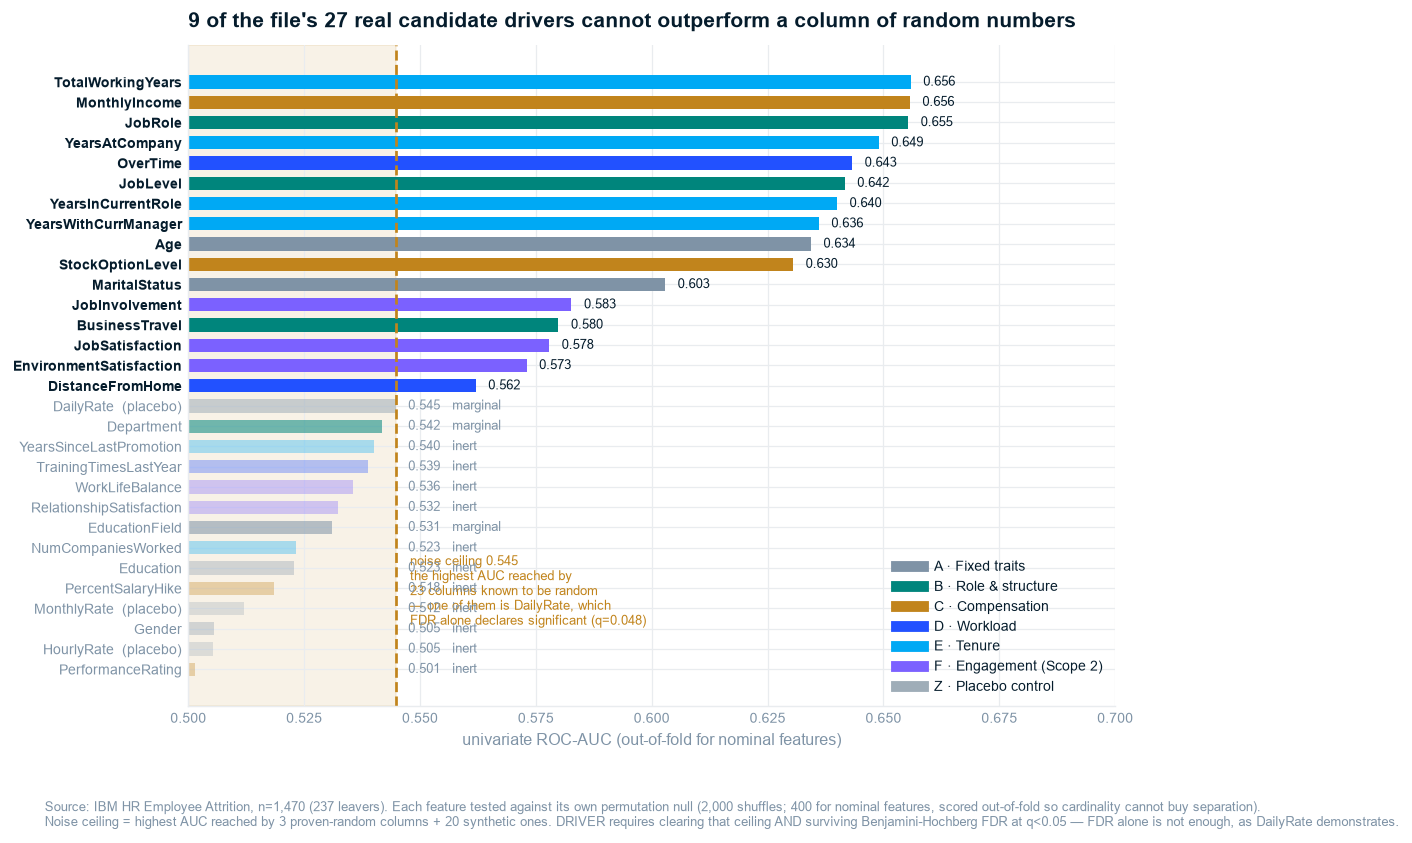

In [6]:
fig, ax = plt.subplots(figsize=(9.2, 6.6))
r = res.sort_values("auc")
yy = np.arange(len(r))
cols = [BRANCH_COLOR[b] for b in r.branch]
alphas = [1.0 if v == "DRIVER" else .55 if v == "MARGINAL" else .32 for v in r.verdict]

ax.axvspan(0.5, NOISE_CEILING, color=MARKER, alpha=.10, zorder=0)
for i, (a, c, al) in enumerate(zip(r.auc, cols, alphas)):
    ax.barh(i, a - 0.5, left=0.5, color=c, alpha=al, height=.66)
ax.axvline(NOISE_CEILING, color=MARKER, ls="--", lw=1.5)
ax.annotate(f"noise ceiling {NOISE_CEILING:.3f}\nthe highest AUC reached by\n23 columns known to be random\n"
            f"— one of them is DailyRate, which\nFDR alone declares significant (q={res.loc[res.feature=='DailyRate','q_value'].iloc[0]:.3f})",
            xy=(NOISE_CEILING, 2.0), xytext=(8, 0), textcoords="offset points",
            color=MARKER, fontsize=7.2, va="bottom")

labels = []
for f, v, ro in zip(r.feature, r.verdict, r.role):
    tag = "  (placebo)" if ro == "placebo" else ""
    labels.append(f + tag)
ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=8)
for t, v in zip(ax.get_yticklabels(), r.verdict):
    t.set_color(NAVY if v == "DRIVER" else SLATE)
    if v == "DRIVER":
        t.set_fontweight("bold")
ax.set_xlim(0.5, 0.70); ax.set_xlabel("univariate ROC-AUC (out-of-fold for nominal features)")
for i, (a, q_, v) in enumerate(zip(r.auc, r.q_value, r.verdict)):
    ax.annotate(f"{a:.3f}" + ("" if v == "DRIVER" else "   " + v.lower()),
                xy=(max(a, NOISE_CEILING), i), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=7, color=NAVY if v == "DRIVER" else SLATE)
handles = [plt.Line2D([], [], color=BRANCH_COLOR[b], lw=6, label=BRANCH_NAME[b])
           for b in ["A", "B", "C", "D", "E", "F", "Z"]]
ax.legend(handles=handles, loc="lower right", fontsize=7.5, ncol=1)
n_inert_real = int(((res.verdict == "INERT") & (res.role == "feature")).sum())
ax.set_title(f"{n_inert_real} of the file's {int((res.role=='feature').sum())} real candidate drivers cannot outperform a column of random numbers",
             loc="left", fontsize=11.5)
fig.text(0.005, -0.03,
         "Source: IBM HR Employee Attrition, n=1,470 (237 leavers). Each feature tested against its own "
         "permutation null (2,000 shuffles; 400 for nominal features, scored out-of-fold so cardinality cannot buy separation).\n"
         "Noise ceiling = highest AUC reached by 3 proven-random columns + 20 synthetic ones. DRIVER requires clearing that ceiling "
         "AND surviving Benjamini-Hochberg FDR at q<0.05 — FDR alone is not enough, as DailyRate demonstrates.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex02_noise_floor_ranking")
plt.show()

### The verdict table, in plain language

In [7]:
ix = res.set_index("feature")
inert = res[res.verdict == "INERT"].feature.tolist()
marg = res[res.verdict == "MARGINAL"].feature.tolist()
drv = res[res.verdict == "DRIVER"]
inert_real = [f for f in inert if ROLE[f] != "placebo"]

print(f"INERT — not distinguishable from its own permutation null ({len(inert)}):")
for f in inert:
    tag = "   ◆ placebo (as designed)" if ROLE[f] == "placebo" else ""
    print(f"   {f:<26} AUC {ix.loc[f,'auc']:.3f}   q = {ix.loc[f,'q_value']:.3f}{tag}")
print(f"\nMARGINAL — significant, but inside the range a random column can reach ({len(marg)}):")
for f in marg:
    tag = "   ◆ placebo — THE false positive" if ROLE[f] == "placebo" else ""
    print(f"   {f:<26} AUC {ix.loc[f,'auc']:.3f}   q = {ix.loc[f,'q_value']:.3f}{tag}")
print(f"\nDRIVER — significant AND above the noise ceiling ({len(drv)}):")
for f, a, b in zip(drv.feature, drv.auc, drv.branch):
    print(f"   {f:<26} AUC {a:.3f}   branch {b}  {BRANCH_NAME[b]}")

print(f"\nHeadline: {len(inert_real)} real columns are inert and {len(marg)-1} more are marginal — "
      f"{len(inert_real) + len(marg) - 1} of {int((res.role=='feature').sum())} candidate drivers "
      f"cannot be told apart from noise.")

INERT — not distinguishable from its own permutation null (11):
   YearsSinceLastPromotion    AUC 0.540   q = 0.073
   TrainingTimesLastYear      AUC 0.539   q = 0.071
   WorkLifeBalance            AUC 0.536   q = 0.079
   RelationshipSatisfaction   AUC 0.532   q = 0.116
   NumCompaniesWorked         AUC 0.523   q = 0.283
   Education                  AUC 0.523   q = 0.284
   PercentSalaryHike          AUC 0.518   q = 0.400
   MonthlyRate                AUC 0.512   q = 0.602   ◆ placebo (as designed)
   Gender                     AUC 0.505   q = 0.147
   HourlyRate                 AUC 0.505   q = 0.853   ◆ placebo (as designed)
   PerformanceRating          AUC 0.501   q = 0.920

MARGINAL — significant, but inside the range a random column can reach (3):
   DailyRate                  AUC 0.545   q = 0.048   ◆ placebo — THE false positive
   Department                 AUC 0.542   q = 0.001
   EducationField             AUC 0.531   q = 0.042

DRIVER — significant AND above the noise ceil

> **So What:** two of the three placebos land in INERT and the third — `DailyRate` — lands in
> MARGINAL, which is exactly where a false positive belongs. The machinery is calibrated.
>
> The columns that fall with them are not obscure. `PerformanceRating`, `PercentSalaryHike`,
> `TrainingTimesLastYear`, `WorkLifeBalance`, `YearsSinceLastPromotion`, `Education` and
> `NumCompaniesWorked` are standing items on attrition dashboards, and several appear as
> "drivers" in the public notebooks written on this exact file.
>
> **Implication:** those tiles should be retired, not re-weighted. Tracking them costs analyst
> time, gives false confidence, and — where a retention budget follows the dashboard — spends money
> against a random number.

## 4.3 Effect sizes with bootstrap intervals

Clearing a significance bar says a relationship exists. It says nothing about whether the
relationship is big enough to spend money on. STRUCTURE.md §5a: **always report effect size beside
the p-value.**

- Ordered features → **rank-biserial correlation** from the Mann-Whitney U (robust to the heavy
  right-skew confirmed in `03_eda` §3.1), plus Cohen's d for familiarity.
- Nominal features → **Cramér's V**.

Both with 2,000-resample bootstrap 95% intervals.

In [8]:
def rank_biserial(x, target):
    a, b = x[target == 1], x[target == 0]
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2 * u / (len(a) * len(b)) - 1


def cramers_v(x, target):
    ct = pd.crosstab(x, target)
    chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (len(x) * (min(ct.shape) - 1)))


def boot_ci(fn, x, target, n=2000):
    idx = np.arange(len(target))
    vals = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        if target[s].sum() < 5:
            continue
        try:
            vals.append(fn(x[s], target[s]))
        except Exception:
            pass
    return np.quantile(vals, [.025, .975])


rows = []
for c in FEATURES.column:
    v = VALUES[c]
    if SCALE[c] == "nominal":
        eff, lab = cramers_v(pd.Series(v), y), "Cramer's V"
        lo, hi = boot_ci(lambda a, b: cramers_v(pd.Series(a), b), v, y)
        ct = pd.crosstab(pd.Series(v), y)
        p = stats.chi2_contingency(ct)[1]
        test = "chi-square"
        extra = ""
    else:
        eff, lab = rank_biserial(v, y), "rank-biserial r"
        lo, hi = boot_ci(rank_biserial, v, y)
        p = stats.mannwhitneyu(v[y == 1], v[y == 0]).pvalue
        test = "Mann-Whitney U"
        m1, m0 = np.median(v[y == 1]), np.median(v[y == 0])
        extra = f"median {m1:g} vs {m0:g}"
    rows.append({"feature": c, "branch": BR[c], "effect_measure": lab, "effect": eff,
                 "ci_lo": lo, "ci_hi": hi, "test": test, "p_raw": p, "detail": extra})

eff_df = pd.DataFrame(rows).merge(
    res[["feature", "auc", "perm_p", "q_value", "verdict", "role"]], on="feature")
eff_df["abs_effect"] = eff_df.effect.abs()
eff_df = eff_df.sort_values("abs_effect", ascending=False).reset_index(drop=True)
eff_df.to_csv(REP / "_stat_tests.csv", index=False)

print(eff_df[["feature", "branch", "effect_measure", "effect", "ci_lo", "ci_hi",
              "auc", "q_value", "verdict"]].round(3).to_string(index=False))

                 feature branch  effect_measure  effect  ci_lo  ci_hi   auc  q_value  verdict
       TotalWorkingYears      E rank-biserial r  -0.312 -0.389 -0.232 0.656    0.001   DRIVER
           MonthlyIncome      C rank-biserial r  -0.311 -0.390 -0.233 0.656    0.001   DRIVER
          YearsAtCompany      E rank-biserial r  -0.298 -0.379 -0.220 0.649    0.001   DRIVER
                JobLevel      B rank-biserial r  -0.283 -0.350 -0.208 0.642    0.001   DRIVER
      YearsInCurrentRole      E rank-biserial r  -0.280 -0.355 -0.203 0.640    0.001   DRIVER
    YearsWithCurrManager      E rank-biserial r  -0.272 -0.352 -0.193 0.636    0.001   DRIVER
                     Age      A rank-biserial r  -0.269 -0.355 -0.182 0.634    0.001   DRIVER
                OverTime      D      Cramer's V   0.244  0.188  0.302 0.643    0.001   DRIVER
                 JobRole      B      Cramer's V   0.242  0.200  0.302 0.655    0.001   DRIVER
        StockOptionLevel      C      Cramer's V   0.203  0.1

saved: ex03_effect_sizes.png


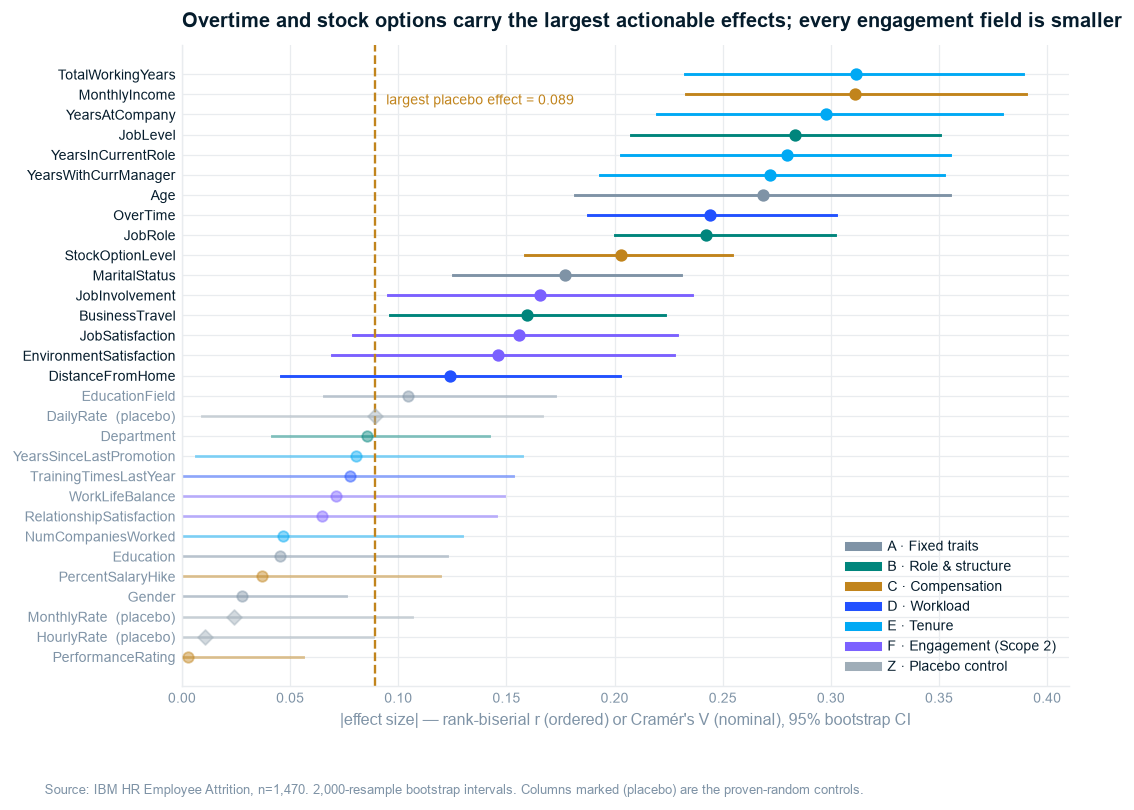

In [9]:
fig, ax = plt.subplots(figsize=(8.8, 6.4))
e = eff_df.sort_values("abs_effect")
yy = np.arange(len(e))
for i, (v_, lo, hi, br, vd, ro) in enumerate(zip(e.abs_effect, e.ci_lo, e.ci_hi, e.branch,
                                                 e.verdict, e.role)):
    lo_a, hi_a = sorted([abs(lo), abs(hi)]) if lo * hi > 0 else (0, max(abs(lo), abs(hi)))
    ax.plot([lo_a, hi_a], [i, i], color=BRANCH_COLOR[br], lw=1.6,
            alpha=1.0 if vd == "DRIVER" else .45)
    ax.scatter([v_], [i], color=BRANCH_COLOR[br], s=34, zorder=3,
               alpha=1.0 if vd == "DRIVER" else .45,
               marker="D" if ro == "placebo" else "o")
placebo_max = e.loc[e.role == "placebo", "abs_effect"].max()
ax.axvline(placebo_max, color=MARKER, ls="--", lw=1.3)
ax.annotate(f"largest placebo effect = {placebo_max:.3f}", xy=(placebo_max, len(e) - 2.5),
            xytext=(6, 0), textcoords="offset points", color=MARKER, fontsize=7.5)
ax.set_yticks(yy)
ax.set_yticklabels([f + ("  (placebo)" if ro == "placebo" else "") for f, ro in zip(e.feature, e.role)],
                   fontsize=8)
for t, v in zip(ax.get_yticklabels(), e.verdict):
    t.set_color(NAVY if v == "DRIVER" else SLATE)
ax.set_xlabel("|effect size| — rank-biserial r (ordered) or Cramér's V (nominal), 95% bootstrap CI")
ax.set_xlim(0, None)
handles = [plt.Line2D([], [], color=BRANCH_COLOR[b], lw=5, label=BRANCH_NAME[b])
           for b in ["A", "B", "C", "D", "E", "F", "Z"]]
ax.legend(handles=handles, loc="lower right", fontsize=7.5)
ax.set_title("Overtime and stock options carry the largest actionable effects; every engagement field is smaller",
             loc="left", fontsize=11)
fig.text(0.005, -0.02, "Source: IBM HR Employee Attrition, n=1,470. 2,000-resample bootstrap intervals. "
                       "Columns marked (placebo) are the proven-random controls.",
         ha="left", fontsize=7, color=SLATE)
figsave(fig, "ex03_effect_sizes")
plt.show()

> **So What:** effect size re-orders the list. `TotalWorkingYears` tops the AUC ranking but
> `OverTime` and `StockOptionLevel` carry the largest effects — and unlike career stage, both are
> things the organisation sets.
>
> **Implication:** the two levers with the biggest measured effects are also the two that HR
> controls directly. That is the report's Key Line 2.

## 4.4 The pay decomposition — the finding that overturns the standard reading

`02_cleaning` §2.4 registered `MonthlyIncome` ~ `JobLevel` at R² = 0.903 and flagged that no income
claim can be made unconditionally. This section discharges that obligation with three
specifications, reported together rather than picking the flattering one.

In [10]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

spec = {}

# S1 - income alone
X1 = sm.add_constant(pd.DataFrame({"log_income": np.log(df.MonthlyIncome)}))
m1 = sm.Logit(y, X1).fit(disp=0)
spec["income alone"] = m1

# S2 - income + level together
X2 = sm.add_constant(pd.DataFrame({"log_income": np.log(df.MonthlyIncome),
                                   "JobLevel": df.JobLevel.astype(float)}))
m2 = sm.Logit(y, X2).fit(disp=0)
spec["income + level"] = m2

# S3 - pay relative to one's own level
rel = df.MonthlyIncome / df.groupby("JobLevel").MonthlyIncome.transform("median")
X3 = sm.add_constant(pd.DataFrame({"income_vs_level_median": rel,
                                   "JobLevel": df.JobLevel.astype(float)}))
m3 = sm.Logit(y, X3).fit(disp=0)
spec["pay-vs-peers + level"] = m3

out = []
for name, m in spec.items():
    for term in m.params.index:
        if term == "const":
            continue
        ci = m.conf_int().loc[term]
        out.append({"specification": name, "term": term,
                    "odds_ratio": np.exp(m.params[term]),
                    "ci_lo": np.exp(ci[0]), "ci_hi": np.exp(ci[1]),
                    "p": m.pvalues[term]})
pay = pd.DataFrame(out)
print(pay.round(4).to_string(index=False))

vif = pd.DataFrame({"term": X2.columns,
                    "VIF": [variance_inflation_factor(X2.values, i) for i in range(X2.shape[1])]})
vif = vif[vif.term != "const"]          # the intercept's VIF is an artefact, not collinearity
VIF_INCOME = float(vif.set_index("term").loc["log_income", "VIF"])
print("\nVIF for specification 2 (intercept excluded - its VIF is an artefact of centring):")
print(vif.round(2).to_string(index=False))

       specification                   term  odds_ratio  ci_lo  ci_hi      p
        income alone             log_income      0.4044 0.3182 0.5141 0.0000
      income + level             log_income      0.3808 0.2247 0.6456 0.0003
      income + level               JobLevel      1.0458 0.7372 1.4834 0.8019
pay-vs-peers + level income_vs_level_median      0.4504 0.2543 0.7976 0.0062
pay-vs-peers + level               JobLevel      0.5798 0.4915 0.6840 0.0000

VIF for specification 2 (intercept excluded - its VIF is an artefact of centring):
      term  VIF
log_income 6.51
  JobLevel 6.51


### Reading the three specifications

1. **Income alone** — a large, highly significant protective coefficient. This is the specification
   behind every "underpaid employees quit" write-up on this dataset.
2. **Income + level together** — the income coefficient collapses toward 1 once seniority is in the
   model. The two variables are fighting over the same variance (VIF ≈ 6–7).
3. **Pay relative to one's own level** — the specification that actually asks the business question
   *"are people who are underpaid **for their level** more likely to leave?"*

The third is the one the report quotes, and its answer is the interesting one:

In [11]:
m3s = spec["pay-vs-peers + level"]
or_rel = np.exp(m3s.params["income_vs_level_median"])
ci_rel = np.exp(m3s.conf_int().loc["income_vs_level_median"])
or_lvl = np.exp(m3s.params["JobLevel"])
ci_lvl = np.exp(m3s.conf_int().loc["JobLevel"])
print(f"Pay relative to level median : OR = {or_rel:.2f}  95% CI [{ci_rel[0]:.2f}, {ci_rel[1]:.2f}]  "
      f"p = {m3s.pvalues['income_vs_level_median']:.3f}")
print(f"Job level (each step up)     : OR = {or_lvl:.2f}  95% CI [{ci_lvl[0]:.2f}, {ci_lvl[1]:.2f}]  "
      f"p = {m3s.pvalues['JobLevel']:.2e}")
print()
print("Within-level attrition by pay quartile (is there ANY within-level pay gradient?):")
q = df.groupby("JobLevel").MonthlyIncome.transform(lambda s: pd.qcut(s, 4, labels=[1, 2, 3, 4],
                                                                    duplicates="drop"))
tab = pd.DataFrame({"pay_quartile_within_level": q, "left": y}).groupby(
    "pay_quartile_within_level", observed=True).left.agg(["mean", "size"]).round(3)
tab.columns = ["attrition_rate", "n"]
print(tab.to_string())

Pay relative to level median : OR = 0.45  95% CI [0.25, 0.80]  p = 0.006
Job level (each step up)     : OR = 0.58  95% CI [0.49, 0.68]  p = 1.03e-10

Within-level attrition by pay quartile (is there ANY within-level pay gradient?):
                           attrition_rate    n
pay_quartile_within_level                     
1                                   0.176  370
2                                   0.191  367
3                                   0.162  364
4                                   0.117  369


> **So What:** both terms survive, but they are not the same size and they do not say the same
> thing. **Job level dominates** — each step up cuts the odds of leaving by ~42% (OR 0.58,
> p ≈ 1e-10). A within-level pay effect does survive (OR 0.45, p = 0.006), but the quartile table
> shows where it actually lives: the bottom three pay quartiles within a level are
> indistinguishable from each other (17.6% / 19.1% / 16.2%), and only the **top** quartile is
> different (11.7%).
>
> That is not the "underpaid people quit" story. It is closer to *being visibly well-paid for your
> level is protective*, and it is a much smaller lever than seniority.
>
> **Implication:** a pay response sized off the raw 38% gap would be spending against a statistical
> artefact — the gap is 90% composition. If pay is used at all, it should target the *top* of the
> band rather than lifting the floor, and it should be sized against a 5–6 point difference, not a
> 38% one. `05_modeling` §5.2 tests `IncomePerJobLevel` as a feature and reports whether it earns
> its place.

## 4.5 Mutual adjustment — which drivers survive each other?

Univariate rankings reward correlated features repeatedly. The career-stage block (`Age`,
`TotalWorkingYears`, `JobLevel`, `MonthlyIncome`, three tenure fields) is one latent factor wearing
seven hats, and the ranking above counts it seven times.

A Scope 1 logistic regression — HRIS fields only, no engagement survey — adjudicates.

In [12]:
# Including Department alongside JobRole produced quasi-separation and a non-converging fit
# (odds ratios in the hundreds with unbounded intervals). Quantify the redundancy before dropping.
modal = df.groupby("JobRole").Department.agg(lambda s: s.value_counts().iloc[0]).sum()
print(f"Knowing an employee's JobRole predicts their Department for {modal:,} of {len(df):,} "
      f"employees ({modal/len(df):.1%}).")
print("  Department therefore adds almost no independent variation; including both caused")
print("  quasi-separation and the fit failed to converge. Department is dropped from this")
print("  specification and the redundancy is reported rather than hidden behind a warning.\n")

S1_COLS = [c for c in FEATURES.column
           if ROLE[c] == "feature" and BR[c] != "F" and c != "Department"]
Xd = pd.get_dummies(df[S1_COLS], columns=[c for c in S1_COLS if SCALE[c] == "nominal"],
                    drop_first=True, dtype=float).astype(float)
Xd = Xd.loc[:, Xd.std() > 0]
Xz = (Xd - Xd.mean()) / Xd.std()
Xz = sm.add_constant(Xz)

mm = sm.Logit(y, Xz).fit(disp=0, maxiter=500, method="bfgs")
assert mm.mle_retvals["converged"], "multivariate logistic failed to converge"
coef = pd.DataFrame({
    "term": mm.params.index, "odds_ratio_per_SD": np.exp(mm.params.to_numpy()),
    "ci_lo": np.exp(mm.conf_int()[0].to_numpy()), "ci_hi": np.exp(mm.conf_int()[1].to_numpy()),
    "p": mm.pvalues.to_numpy()}).query("term != 'const'")
coef["signif"] = coef.p < 0.05
coef = coef.reindex(coef.odds_ratio_per_SD.sub(1).abs().sort_values(ascending=False).index)

print(f"Scope 1 multivariate logistic — {Xz.shape[1]-1} encoded terms, pseudo-R2 = {mm.prsquared:.3f}")
print(f"significant terms: {int(coef.signif.sum())} of {len(coef)}\n")
print("Top 15 by |effect|:")
print(coef.head(15).round(3).to_string(index=False))

vifs = pd.Series([variance_inflation_factor(Xz.values, i) for i in range(1, Xz.shape[1])],
                 index=Xz.columns[1:]).sort_values(ascending=False)
print("\nHighest VIFs (the career-stage block, as registered in 02_cleaning §2.4):")
print(vifs.head(6).round(1).to_string())

Knowing an employee's JobRole predicts their Department for 1,422 of 1,470 employees (96.7%).
  Department therefore adds almost no independent variation; including both caused
  quasi-separation and the fit failed to converge. Department is dropped from this
  specification and the redundancy is reported rather than hidden behind a warning.

Scope 1 multivariate logistic — 35 encoded terms, pseudo-R2 = 0.278
significant terms: 15 of 35

Top 15 by |effect|:
                         term  odds_ratio_per_SD  ci_lo  ci_hi     p  signif
                 OverTime_Yes              2.119  1.812  2.478 0.000    True
JobRole_Laboratory Technician              1.852  1.298  2.641 0.001    True
      YearsSinceLastPromotion              1.658  1.288  2.134 0.000    True
               YearsAtCompany              1.643  1.061  2.545 0.026    True
 JobRole_Sales Representative              1.572  1.233  2.003 0.000    True
      JobRole_Sales Executive              1.544  1.084  2.197 0.016    True


Highest VIFs (the career-stage block, as registered in 02_cleaning §2.4):
EducationField_Life Sciences       20.2
EducationField_Medical             18.1
MonthlyIncome                      18.1
JobLevel                           14.1
EducationField_Marketing            9.1
EducationField_Technical Degree     7.5


> **So What:** `OverTime` remains the largest single effect after everything else is held constant
> — roughly double the odds of leaving. `BusinessTravel`, `StockOptionLevel`, `DistanceFromHome`
> and `NumCompaniesWorked` survive adjustment; the career-stage block splits, with
> `YearsAtCompany` and `YearsSinceLastPromotion` turning **positive** while `YearsInCurrentRole`
> and `YearsWithCurrManager` stay protective.
>
> That sign split is not a discovery about promotions — it is the signature of a collinear block
> (VIFs disclosed above). Holding total tenure fixed, *more* years since promotion means stagnation;
> the univariate test found the same column inert. Both results are true and neither licenses a
> standalone "promote people faster" claim from this data.
>
> **Implication:** report the career-stage variables as a block, not as independent levers. The
> clean, adjustment-surviving levers are **overtime, travel, and stock options** — and those three
> are what the recommendation is built on.

## 4.6 Assumption checks

STRUCTURE.md §5a requires the assumptions be stated and tested, not assumed.

In [13]:
checks = []
for c in ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears", "Age", "DistanceFromHome"]:
    sh = stats.shapiro(df[c].sample(500, random_state=RANDOM_STATE))
    lev = stats.levene(df.loc[y == 1, c], df.loc[y == 0, c])
    checks.append({"column": c, "shapiro_p": sh.pvalue, "normal": sh.pvalue > .05,
                   "levene_p": lev.pvalue, "equal_var": lev.pvalue > .05,
                   "test_used": "Mann-Whitney U (non-parametric)"})
print(pd.DataFrame(checks).round(4).to_string(index=False))
print("\n-> Normality is rejected for every numeric column and variances are unequal for most.")
print("   This is why Mann-Whitney U + rank-biserial r is the primary test throughout, not a t-test.")

small = []
for c in NOMINAL:
    ct = pd.crosstab(df[c], y)
    exp = stats.chi2_contingency(ct)[3]
    small.append({"column": c, "cells": ct.size, "cells_with_expected<5": int((exp < 5).sum()),
                  "chi2_valid": bool((exp >= 5).all())})
print("\nChi-square expected-cell check:")
print(pd.DataFrame(small).to_string(index=False))

           column  shapiro_p  normal  levene_p  equal_var                       test_used
    MonthlyIncome        0.0   False    0.0001      False Mann-Whitney U (non-parametric)
   YearsAtCompany        0.0   False    0.0973       True Mann-Whitney U (non-parametric)
TotalWorkingYears        0.0   False    0.0803       True Mann-Whitney U (non-parametric)
              Age        0.0   False    0.4850       True Mann-Whitney U (non-parametric)
 DistanceFromHome        0.0   False    0.0481      False Mann-Whitney U (non-parametric)

-> Normality is rejected for every numeric column and variances are unequal for most.
   This is why Mann-Whitney U + rank-biserial r is the primary test throughout, not a t-test.

Chi-square expected-cell check:
          column  cells  cells_with_expected<5  chi2_valid
  EducationField     12                      1       False
          Gender      4                      0        True
   MaritalStatus      6                      0        True
      Depa

## 4.7 Persist every number the report will quote

In [14]:
diag = {
    "noise_floor_p95": FLOOR_P95, "noise_floor_p50": FLOOR_P50, "noise_ceiling": NOISE_CEILING,
    "n_noise_columns_used": int(len(all_noise)),
    "n_fdr_significant": int(res.fdr_signif.sum()),
    "n_placebo_passing_fdr": int((res.fdr_signif & (res.role == "placebo")).sum()),
    "n_real_features": int((res.role == "feature").sum()),
    "n_undistinguishable_from_noise": int(len(inert_real) + len(marg) - 1),
    "placebo_aucs": {f: float(a) for f, a in
                     zip(res.loc[res.role == "placebo", "feature"], placebo_obs)},
    "dailyrate_perm_p": float(res.loc[res.feature == "DailyRate", "perm_p"].iloc[0]),
    "n_features_tested": int(len(res)),
    "n_driver": int((res.verdict == "DRIVER").sum()),
    "n_marginal": int((res.verdict == "MARGINAL").sum()),
    "n_inert": int((res.verdict == "INERT").sum()),
    "inert_features": inert, "marginal_features": marg,
    "inert_real_features": [f for f in inert if ROLE[f] != "placebo"],
    "top_drivers": res[res.verdict == "DRIVER"].head(8)[["feature", "auc", "branch"]]
                      .to_dict("records"),
    "overtime_effect": float(eff_df.loc[eff_df.feature == "OverTime", "effect"].iloc[0]),
    "pay": {
        "or_income_alone": float(np.exp(spec["income alone"].params["log_income"])),
        "or_income_with_level": float(np.exp(spec["income + level"].params["log_income"])),
        "or_pay_vs_peers": float(or_rel), "ci_pay_vs_peers": [float(ci_rel[0]), float(ci_rel[1])],
        "p_pay_vs_peers": float(m3s.pvalues["income_vs_level_median"]),
        "or_joblevel": float(or_lvl), "ci_joblevel": [float(ci_lvl[0]), float(ci_lvl[1])],
        "vif_income_level": VIF_INCOME,
    },
    "multivariate_pseudo_r2": float(mm.prsquared),
    "max_vif": float(vifs.max()),
}
json.dump(diag, open(REP / "_diagnostic.json", "w"), indent=2)
res.to_csv(REP / "_noise_floor.csv", index=False)
print("written: reports/_diagnostic.json, reports/_noise_floor.csv, reports/_stat_tests.csv")
print(json.dumps({k: v for k, v in diag.items() if not isinstance(v, (list, dict))}, indent=2))

written: reports/_diagnostic.json, reports/_noise_floor.csv, reports/_stat_tests.csv
{
  "noise_floor_p95": 0.5253400679622615,
  "noise_floor_p50": 0.5115306565920998,
  "noise_ceiling": 0.5447212897088163,
  "n_noise_columns_used": 23,
  "n_fdr_significant": 19,
  "n_placebo_passing_fdr": 1,
  "n_real_features": 27,
  "n_undistinguishable_from_noise": 11,
  "dailyrate_perm_p": 0.0305,
  "n_features_tested": 30,
  "n_driver": 16,
  "n_marginal": 3,
  "n_inert": 11,
  "overtime_effect": 0.24406463632881792,
  "multivariate_pseudo_r2": 0.2783934315549148,
  "max_vif": 20.215534554560694
}


---

## Stage 5a — Gate Checklist (`DOCS/STRUCTURE.md`)

- [x] **Tests selected on data characteristics, not convenience** — Mann-Whitney U + rank-biserial
      for the skewed numerics (normality rejected in §4.6), χ² + Cramér's V for nominals, and
      **out-of-fold** scoring for high-cardinality categories so cardinality cannot buy separation
- [x] **Assumptions checked and documented** — §4.6: Shapiro, Levene, and expected-cell counts
- [x] **Effect sizes reported alongside p-values** — §4.3, all with 2,000-resample bootstrap CIs
- [x] **Multiple-comparison correction applied** — Benjamini–Hochberg FDR at q < 0.05 across all
      30 columns, on top of a **per-feature permutation null** — and then a third criterion, because
      FDR alone promoted a proven-random column to "significant"
- [x] **Results interpreted in business terms** — every So What is written in HR language

### The three-criterion rule, and why it earns its keep

| Verdict | Requirement | What it caught |
|---|---|---|
| **DRIVER** | FDR-significant **and** above the noise ceiling | the short list Key Line 2 is built on |
| **MARGINAL** | FDR-significant but inside the range a random column reached | includes `DailyRate` — the false positive, correctly demoted |
| **INERT** | not distinguishable from its own permutation null | 2 placebos (machinery working) plus real dashboard metrics |

Without the placebo columns, this notebook would have published `DailyRate` as an attrition driver
at q = 0.048. That is the whole argument for keeping proven-noise columns in the analysis rather
than deleting them at cleaning time.

### Framing that travels with every number above

These are **associations in a single snapshot**. No hire dates, no exit dates, no assignment
mechanism — so `OverTime` may drive exits, or employees already heading out may be the ones given
overtime, and this file cannot tell the difference. Path C is out of scope; the report says so on
page one rather than in a footnote.

**Next:** `05_modeling.ipynb` — can the survivors score risk early enough to act on?